In [1]:
import convolution
import numpy as np
from matplotlib import pyplot as plt
import stimulationProtocols
import plot
##############with recovery cycle data from Weidner, corrected

In [2]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal
from numpy import exp,arange
from pylab import meshgrid,cm,imshow,contour,clabel,colorbar,axis,title,show
import pandas as pd
import stimulationProtocols

In [3]:
%matplotlib inline
#best particle
params=[0.22001242418622874, 0.001386879631280578, 0.0, 
        21.800065382804718, 0.10525234957525222, 0.0, 7.530002307671147, 0.5531734919077812, 2.851578017360972, 3.485490643651577]
    

In [8]:
def m(x_arr, y_arr):
    """
    Vectorized version of your memory function m(x, y).
    x_arr, y_arr are NumPy arrays of the same shape.
    Returns a NumPy array of the same shape with the elementwise result.
    """
    # constants, same as in your m(x,y)
    a,b,c, d, e1, e2, f_, g, h, q = [
        0.22001242418622874, 0.001386879631280578, 0.0, 
        21.800065382804718, 0.10525234957525222, 0.0,
        7.530002307671147, 0.5531734919077812, 2.851578017360972,
        3.485490643651577
    ]

    # Prepare output array
    out = np.empty_like(x_arr, dtype=np.float64)

    # Masks for the piecewise conditions:
    mask_x_small  = (x_arr < 0.5)
    mask_y_large  = (y_arr > 0.5)
    mask1 = mask_x_small & mask_y_large         # x<0.5, y>0.001
    mask2 = mask_x_small & ~mask_y_large        # x<0.5, y<=0.001
    mask3 = ~mask_x_small                       # x>=0.5

    # 1) x < 0.5, y > 0.001
    out[mask1] = (
        np.exp(-d * (x_arr[mask1] - e1))
        - np.log(q * y_arr[mask1]) * h * np.exp(-f_ * (x_arr[mask1] - e2))
        + g
    )
    
    # 2) x < 0.5, y <= 0.001
    out[mask2] = (
        np.exp(-d * (x_arr[mask2] - e1))
        - np.log(q * 0.5) * h * np.exp(-f_ * (x_arr[mask2] - e2))
        + g
    )
    
    # 3) x >= 0.5
    #    res = a - b*x - c*y, but clipped to 0 if negative
    tmp = a - b * x_arr[mask3] - c * y_arr[mask3]
    tmp[tmp < 0] = 0
    out[mask3] = tmp

    return out

In [5]:
'''
def m(x, y):
    a,b,c, d, e1, e2, f, g, h, q=[0.22001242418622874, 0.001386879631280578, 0.0, 
        21.800065382804718, 0.10525234957525222, 0.0, 7.530002307671147, 0.5531734919077812, 2.851578017360972, 3.485490643651577]
    if x<0.5:
        if y>0.001:
            return np.exp(-d*(x-e1))-np.log(q*y)*h*np.exp(-f*(x-e2))+g
        else:
            return np.exp(-d*(x-e1))-np.log(q*0.001)*h*np.exp(-f*(x-e2))+g
    else:
        a,b,c=[9.98896682e+00, 2.15538679e-05, 4.97773116e-01]
        return (a * np.exp(-b * x*1000) + c)/30
'''   

'\ndef m(x, y):\n    a,b,c, d, e1, e2, f, g, h, q=[0.22001242418622874, 0.001386879631280578, 0.0, \n        21.800065382804718, 0.10525234957525222, 0.0, 7.530002307671147, 0.5531734919077812, 2.851578017360972, 3.485490643651577]\n    if x<0.5:\n        if y>0.001:\n            return np.exp(-d*(x-e1))-np.log(q*y)*h*np.exp(-f*(x-e2))+g\n        else:\n            return np.exp(-d*(x-e1))-np.log(q*0.001)*h*np.exp(-f*(x-e2))+g\n    else:\n        a,b,c=[9.98896682e+00, 2.15538679e-05, 4.97773116e-01]\n        return (a * np.exp(-b * x*1000) + c)/30\n'

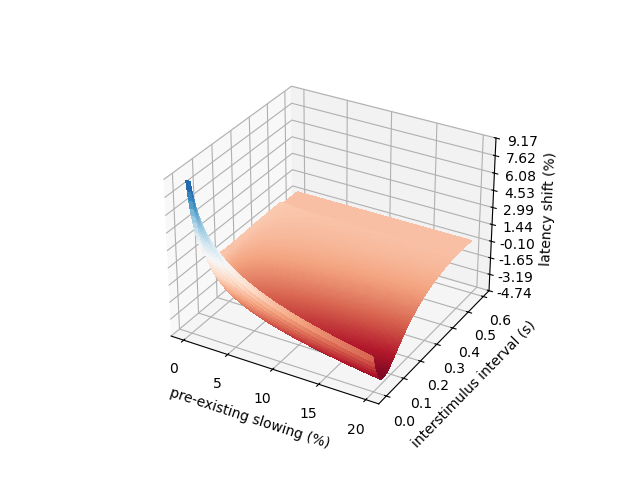

In [6]:
#visualize memory function
%matplotlib ipympl
x = arange(0,0.6,0.005)#inter stimulus interval (s)
y = arange(0,20,0.1)#pre-existing slowing (%)
X,Y = meshgrid(x, y) # grid of point

#print(x)
M=np.empty(shape=(len(y),len(x)))
#print(M)
for i in range(len(x)):
    for j in range(len(y)):
        M[j][i]=m(x[i],y[j])

#print(M)
#M = m(X, Y) # evaluation of the function on the grid
#print(M)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(Y, X, M, rstride=1, cstride=1, 
                      cmap=cm.RdBu,linewidth=0, antialiased=False, 
                       vmin=-5, vmax=10)

ax.zaxis.set_major_locator(LinearLocator(10))
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

ax.set_xlabel('pre-existing slowing (%)')
ax.set_ylabel('interstimulus interval (s)')
ax.set_zlabel('latency shift (%)')

#fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

[8, 16, 24, 32, 40, 48, 56, 64, 72, 80, 88, 96, 104, 112, 120, 128, 136, 144, 152, 160, 164, 168, 172, 176, 180, 184, 188, 192, 196, 200, 204, 208, 212, 216, 220, 224, 228, 232, 236, 240, 242, 244, 246, 248, 250, 252, 254, 256, 258, 260, 262, 264, 266, 268, 270, 272, 274, 276, 278, 280, 282, 284, 286, 288, 290, 292, 294, 296, 298, 300, 304, 308, 312, 316, 320, 324, 328, 332, 336, 340, 344, 348, 352, 356, 360]
Simulation time: 0.0000815550 min


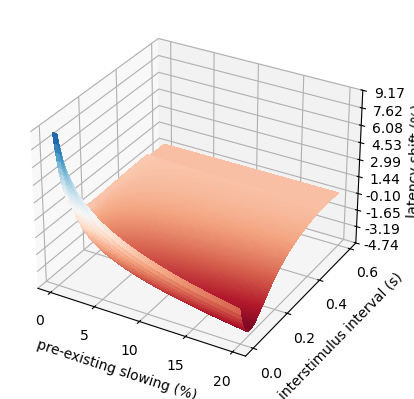

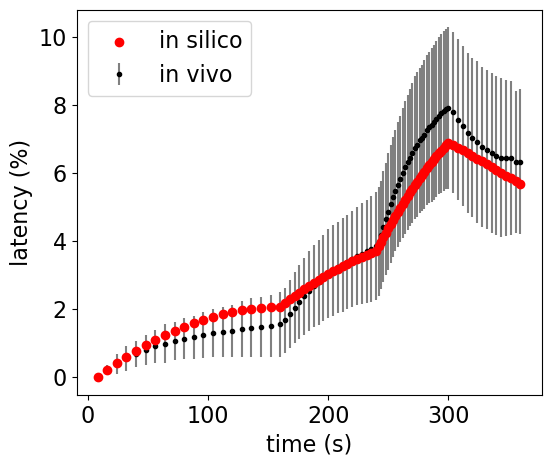

2          0.0
3     0.216804
4     0.397006
5     0.554035
6     0.688578
        ...   
82    6.449219
83    6.444853
84    6.444499
85    6.326756
86    6.340589
Length: 85, dtype: object

In [7]:
%matplotlib inline
data_stim=stimulationProtocols.setStimulationProtocol(11)
print(data_stim)

relLatency=convolution.convolution_vec(data_stim, m)
#print(relLatency)
plt.rcParams.update({'font.size': 16}) 
plot.plotRealSim("Data/DatenELID_Cleaned.xlsx", relLatency, data_stim, "CMi", True, savefile="2D_ELID")

Simulation time: 0.0000384883 min
[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0, 18.0, 26.0, 34.0, 42.0, 50.0, 58.0, 66.0, 74.0, 82.0, 90.0, 98.0, 106.0, 114.0, 122.0, 130.0, 138.0, 146.0, 154.0, 162.0, 170.0, 174.0, 178.0, 182.0, 186.0, 190.0, 194.0, 198.0, 202.0, 206.0, 210.0, 214.0, 218.0, 222.0, 226.0, 230.0, 234.0, 238.0, 242.0, 246.0, 250.0, 252.0, 254.0, 256.0, 258.0, 260.0, 262.0, 264.0, 266.0, 268.0, 270.0, 272.0, 274.0, 276.0, 278.0, 280.0, 282.0, 284.0, 286.0, 288.0, 290.0, 292.0, 294.0, 296.0, 298.0, 300.0, 302.0, 304.0, 306.0, 308.0, 310.0, 314.0, 318.0, 322.0, 326.0, 330.0, 334.0, 338.0, 342.0, 346.0, 350.0, 354.0, 358.0, 362.0, 366.0, 370.0]
[0.         0.21931898 0.43794453 0.65587663 0.8731153  1.08966052
 1.30551231 1.52067065 1.73513556 1.94890703 2.16198505 2.37436964
 2.58606078 2.79705849 3.00736276 3.21697358 3.42589097 3.63411492
 3.84164543 4.04848249 4.04659418 4.03361082 4.00953243 3.974359
 3.92809054 3.

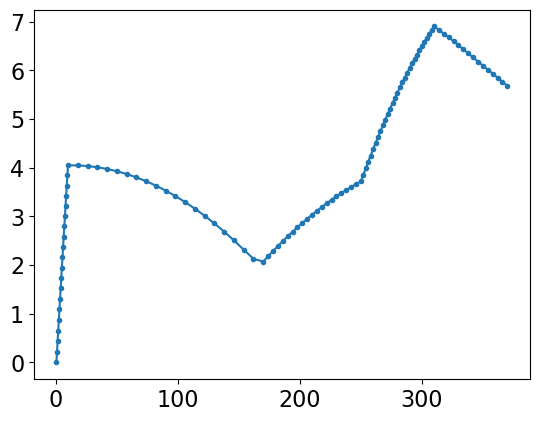

In [8]:
#test
vec=[]
for i in range(1,21):
    vec.append(i*0.5)
lastPulse=20*0.5
#20 pulses at 0.125 Hz -> one pulse every 8 seconds
for i in range(1,21):
    vec.append(lastPulse+i*8)
lastPulse=lastPulse+20*8
#20 pulses at 0.25 Hz -> one pulse every 4 seconds
for i in range(1,21):
    vec.append(lastPulse+i*4)
lastPulse=lastPulse+20*4
#30 pulses at 0.5 Hz -> one pulse every 2 seconds
for i in range(1,31):
    vec.append(lastPulse+i*2)
lastPulse=lastPulse+30*2
#10 pulses at 0.25 Hz -> one pulse every 4 seconds
for i in range(1,16):
    vec.append(lastPulse+i*4)

simLatency=convolution.convolution_vec(vec,m)
print(vec)
print(simLatency)
plt.plot(vec, simLatency, linestyle=None, marker='.')
plt.show()


Simulation time: 0.0001336067 min


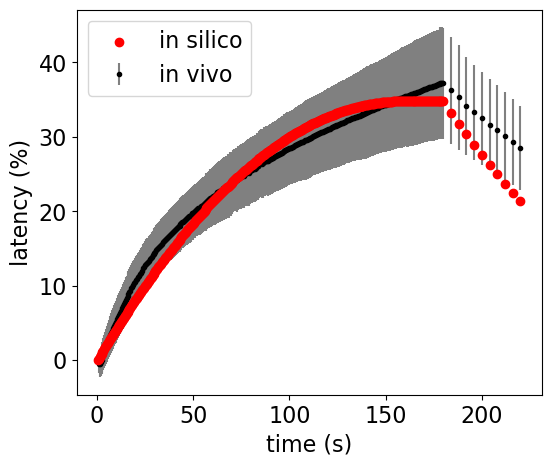

2            0.0
3      -0.452352
4       -0.50299
5      -0.263001
6       0.058648
         ...    
367    31.666662
368    30.955953
369    30.155419
370    29.362378
371    28.560199
Length: 370, dtype: object

In [9]:
data_stim=stimulationProtocols.setStimulationProtocol(15)

relLatency=convolution.convolution_vec(data_stim, m)

plot.plotRealSim("Data/DatenSerra_Cleaned.xlsx", relLatency, data_stim, "CMi", True,savefile="2D_2Hz")


Simulation time: 0.0001558550 min


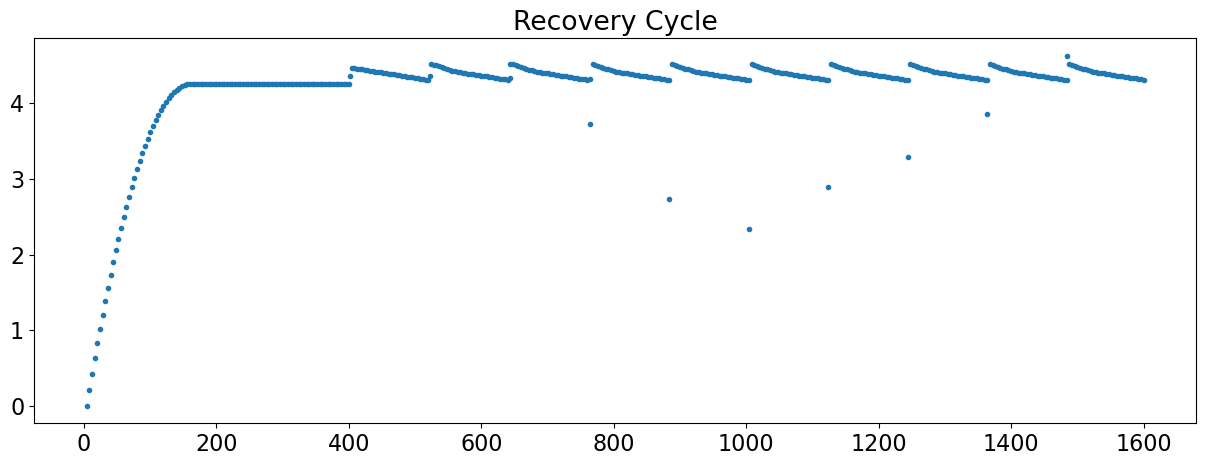

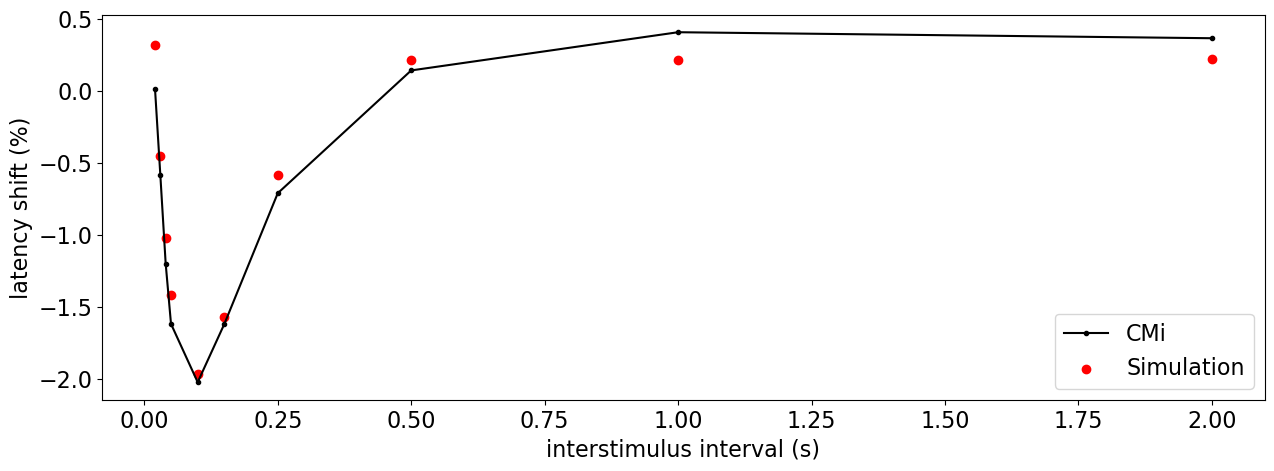

In [12]:
prot="DP"
data_stim=stimulationProtocols.setStimulationProtocol(prot)
#print(stim)

relLatency=convolution.convolution_vec(data_stim, m)
relLatency0=relLatency
plt.rcParams.update({'font.size': 16}) 
plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')
plt.title("Recovery Cycle")
plt.show()
    
fig, ax=plt.subplots(figsize=(15,5))

#[20, 50, 100, 250, 500, 1000, 2000]
#[0, -7.3, -9.06, -3.14, 0.75, 1.89, 1.7]

realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]

plt.plot(extras[::-1],realValues[::-1], linestyle='-', marker='.', label="CMi", color="black")

data_sim=relLatency
if data_sim is not None:
    l=data_sim
    #print(l)
    recoveryCycle=[]
    numberPrevPulses=100
    numberRegPulses=30
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle.append(l[i+2]-l[i])
        #print('###')
        #print(l[i])
        #print(l[i+2])
        #print(l[i+2]-l[i])

    #print(recoveryCycle)
    plt.scatter(extras[::-1], recoveryCycle[::-1], label="Simulation", color="red")
    #ax.set_xticks(range(11))
    #labels=["2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20", "15"]
    #ax.set_xticklabels(labels[::-1])
    plt.xlabel("interstimulus interval (s)")
    plt.ylabel("latency shift (%)")

    plt.legend()
    plt.savefig("Figures/2D_RecoveryCycle.png", bbox_inches='tight')
    plt.show()
    


In [11]:
def protDP(freq):
    #20 pulses at 0.25 Hz -> one pulse every 4 seconds
    #to stabilize latency
    offset=0
    vec=[]
    numberPrevPulses=100
    for i in range(1,numberPrevPulses+1):
        vec.append(offset+i*freq)
    lastPulse=offset+numberPrevPulses*freq
    extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]#distance to next regular puls
    numReg=30#number of regular pulses
    for e in extras:
        #one extra pulse
        vec.append(lastPulse+freq-e)
        #regular pulses
        for i in range(1,numReg+1):
            vec.append(lastPulse+i*freq)
        lastPulse=lastPulse+numReg*freq
    return vec

def getRecoveryCycle(l):
    recoveryCycle=[]
    numberPrevPulses=100
    numberRegPulses=30
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle.append(l[i+2]-l[i])
    return recoveryCycle


Simulation time: 0.0001495750 min
Simulation time: 0.0001468583 min
Simulation time: 0.0001497183 min
Simulation time: 0.0001473017 min
Simulation time: 0.0001467667 min


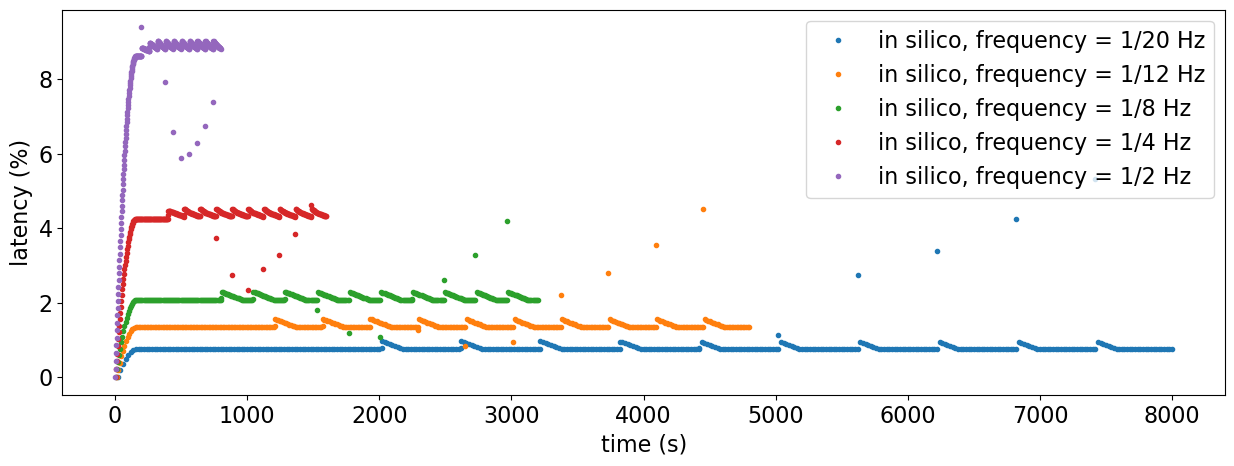

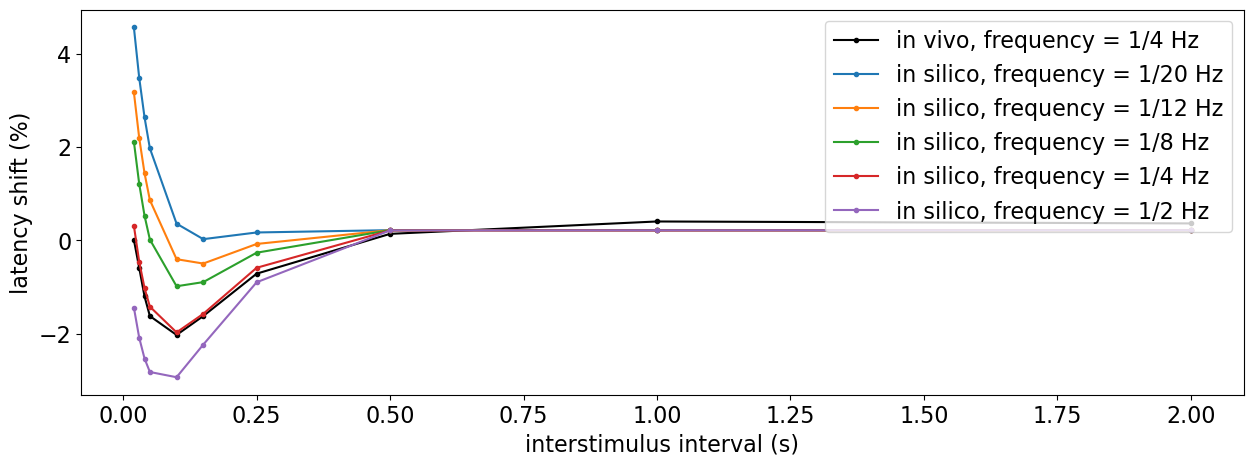

In [12]:
#recovery cycle with different background frequency

data_stim1=protDP(20)
relLatency1=convolution.convolution_vec(data_stim1, m)

data_stim2=protDP(12)
relLatency2=convolution.convolution_vec(data_stim2, m)

data_stim3=protDP(8)
relLatency3=convolution.convolution_vec(data_stim3, m)

data_stim4=protDP(4)
relLatency4=convolution.convolution_vec(data_stim4, m)

data_stim5=protDP(2)
relLatency5=convolution.convolution_vec(data_stim5, m)

plt.rcParams.update({'font.size': 16}) 
plt.figure(figsize=(15,5)) 
plt.plot(data_stim1, relLatency1, marker='.', linestyle='none', label="in silico, frequency = 1/20 Hz")
plt.plot(data_stim2, relLatency2, marker='.', linestyle='none', label="in silico, frequency = 1/12 Hz")
plt.plot(data_stim3, relLatency3, marker='.', linestyle='none', label="in silico, frequency = 1/8 Hz")
plt.plot(data_stim4, relLatency4, marker='.', linestyle='none', label="in silico, frequency = 1/4 Hz")
plt.plot(data_stim5, relLatency5, marker='.', linestyle='none', label="in silico, frequency = 1/2 Hz")
#plt.title("Recovery Cycle")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.legend(loc="upper right")
plt.savefig("Figures/RecoveryCycle2D_1.tiff", dpi=300, bbox_inches='tight')
plt.show()
    
fig, ax=plt.subplots(figsize=(15,5))

#[20, 50, 100, 250, 500, 1000, 2000]
#[0, -7.3, -9.06, -3.14, 0.75, 1.89, 1.7]

realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]

plt.plot(extras[::-1],realValues[::-1], linestyle='-', marker='.', label="in vivo, frequency = 1/4 Hz", color="black")

plt.plot(extras[::-1], getRecoveryCycle(relLatency1)[::-1], marker='.', label="in silico, frequency = 1/20 Hz")
plt.plot(extras[::-1], getRecoveryCycle(relLatency2)[::-1], marker='.', label="in silico, frequency = 1/12 Hz")
plt.plot(extras[::-1], getRecoveryCycle(relLatency3)[::-1], marker='.', label="in silico, frequency = 1/8 Hz")
plt.plot(extras[::-1], getRecoveryCycle(relLatency4)[::-1], marker='.', label="in silico, frequency = 1/4 Hz")
plt.plot(extras[::-1], getRecoveryCycle(relLatency5)[::-1], marker='.', label="in silico, frequency = 1/2 Hz")

plt.xlabel("interstimulus interval (s)")
plt.ylabel("latency shift (%)")

plt.legend()
plt.savefig("Figures/RecoveryCycle2D_2.tiff", dpi=300, bbox_inches='tight')
plt.show()
    


Simulation time: 0.0001748617 min
Simulation time: 0.0002380950 min


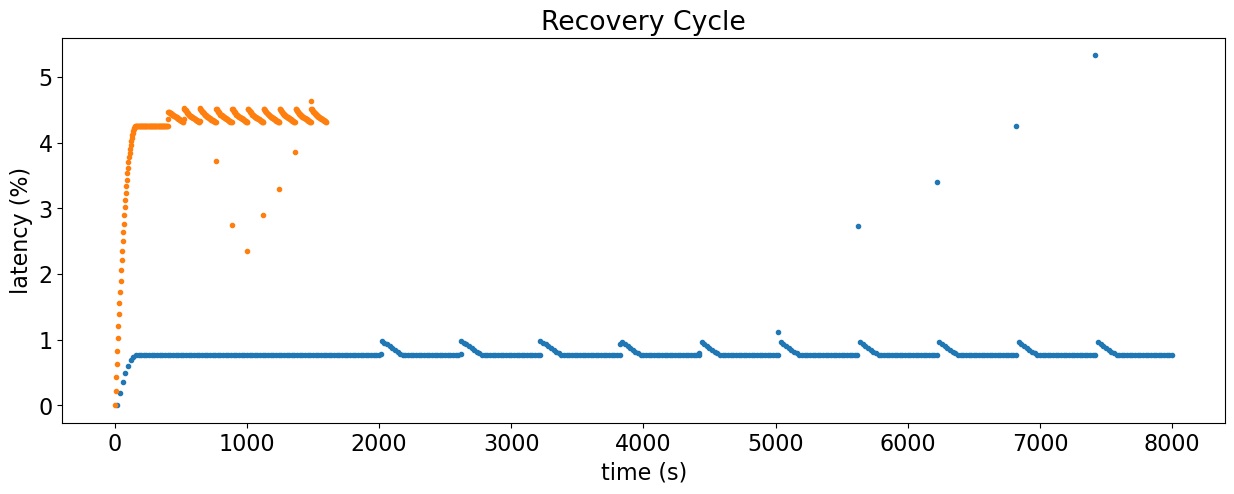

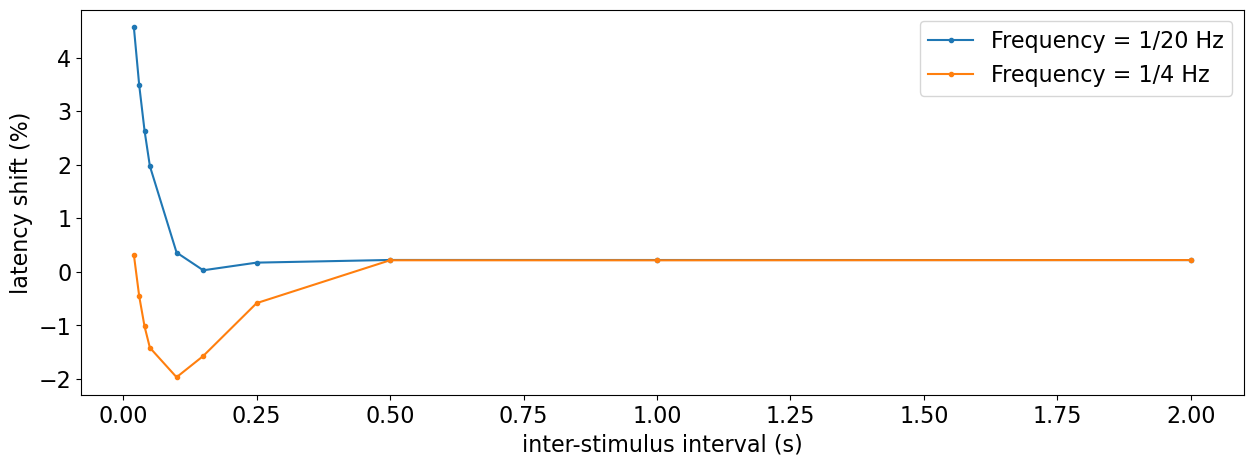

In [13]:
#recovery cycle with different background frequency

data_stim1=protDP(20)
relLatency1=convolution.convolution_vec(data_stim1, m)

data_stim4=protDP(4)
relLatency4=convolution.convolution_vec(data_stim4, m)

plt.figure(figsize=(15,5)) 
plt.plot(data_stim1, relLatency1, marker='.', linestyle='none')
plt.plot(data_stim4, relLatency4, marker='.', linestyle='none')
plt.title("Recovery Cycle")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.show()
    
fig, ax=plt.subplots(figsize=(15,5))

#[20, 50, 100, 250, 500, 1000, 2000]
#[0, -7.3, -9.06, -3.14, 0.75, 1.89, 1.7]

realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]

#plt.plot(extras[::-1],realValues[::-1], linestyle='-', marker='.', label="Real, Frequency = 1/4 Hz", color="black")

plt.plot(extras[::-1], getRecoveryCycle(relLatency1)[::-1], marker='.', label="Frequency = 1/20 Hz")
plt.plot(extras[::-1], getRecoveryCycle(relLatency4)[::-1], marker='.', label="Frequency = 1/4 Hz")

plt.xlabel("inter-stimulus interval (s)")
plt.ylabel("latency shift (%)")

plt.legend()
plt.show()
    


[2.204482619672139, 1.2127016675233941, 0.45396198758864115, 0.28778819256589794, 0.1254033142706551, 0.09330633488241499, 0.0378379552878806, 0.0426578040805406, 0.021418433216553803, 0.024181845365681846]
[2.204482619672139, 1.2127016675233941, 0.45396198758864115, 0.28778819256589794, 0.1254033142706551, 0.09330633488241499, 0.0378379552878806, 0.0426578040805406, 0.021418433216553803, 0.024181845365681846]
Simulation time: 0.0001468400 min


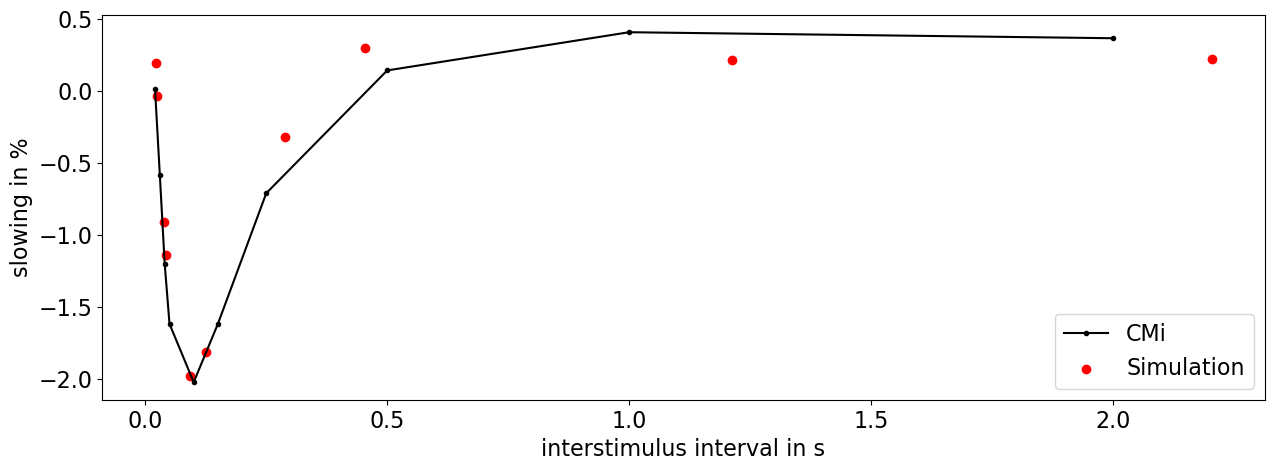

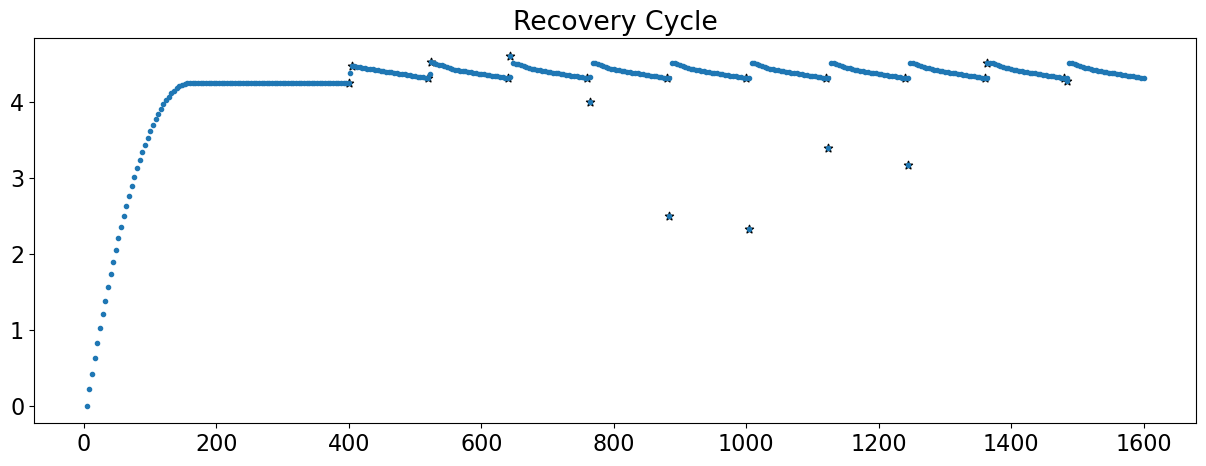

Pearson Correlation coefficient:  0.9194828527729291


In [14]:
#Recovery Cycle with noise
%matplotlib inline
import stimulationProtocols
prot="DP"
#data_stim=stimulationProtocols.setStimulationProtocol(prot)
#20 pulses at 0.25 Hz -> one pulse every 4 seconds
#to stabilize latency
offset=0
numberPrevPulses=100
vec=[]
for i in range(1,numberPrevPulses+1):
    vec.append(offset+i*4)
lastPulse=offset+numberPrevPulses*4
extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]#distance to next regular puls
# add noise
noise=[]
for e in extras:
    noise.append(np.random.normal(e, e*0.2))
#noise = np.random.normal(0, 1, 10)  # Mittelwert 0, Standardabweichung 1
#extras = extras + noise
extras=noise
extras2=extras
print(noise)
print(extras)
numReg=30#number of regular pulses
for e in extras:
    #one extra pulse
    vec.append(lastPulse+4-e)
    #regular pulses
    for i in range(1,numReg+1):
        vec.append(lastPulse+i*4)
    lastPulse=lastPulse+numReg*4
data_stim=vec

relLatency=convolution.convolution_vec(data_stim, m)
relLatency2=relLatency

#plotten  
fig, ax=plt.subplots(figsize=(15,5))
#"2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"
realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner, in ms!!!!!
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extraOriginal=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]
plt.plot(extraOriginal[::-1],realValues[::-1], linestyle='-', marker='.', label="CMi", color="black", zorder=10)

data_sim=relLatency
numberPrevPulses=100
numberRegPulses=30
if data_sim is not None:
    l=data_sim
    #print(l)
    recoveryCycle2=[]
    
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle2.append(l[i+2]-l[i])
        #print('###')
        #print(l[i])
        #print(l[i+2])
        #print(l[i+2]-l[i])

    #print(recoveryCycle)
    plt.scatter(extras[::-1], recoveryCycle2[::-1], label="Simulation", color="red")
    #ax.set_xticks(extraOriginal)
    #labels=["2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"]
    #ax.set_xticklabels(labels[::-1])
    plt.xlabel("interstimulus interval in s")
    plt.ylabel("slowing in %")

    plt.legend()


plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')

for i in range(numberPrevPulses-1,len(data_sim)-2,numberRegPulses+1):
    plt.scatter(data_stim[i], relLatency[i], marker='*', color="black")
    plt.scatter(data_stim[i+2], relLatency[i+2], marker='*', color="black")
    #print('###')
    #print(data_stim[i])
    #print(data_stim[i+1])
    #print(data_stim[i+2])

plt.title("Recovery Cycle")
plt.show()

#calculate correlation

correlation_matrix = np.corrcoef(realValues, recoveryCycle2)
pearson_correlation = correlation_matrix[0, 1]
print("Pearson Correlation coefficient: ", pearson_correlation)

Simulation time: 0.0001541783 min


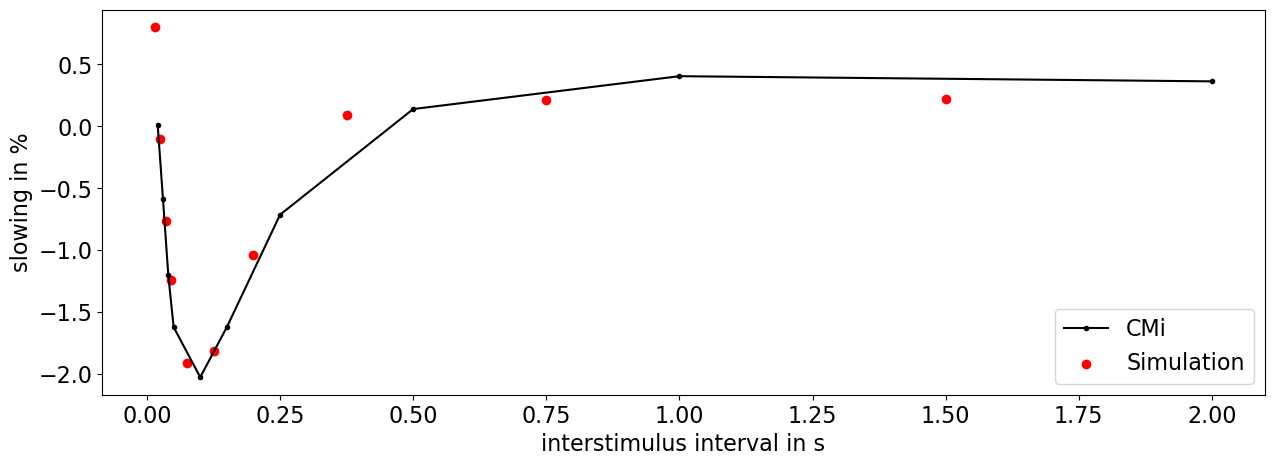

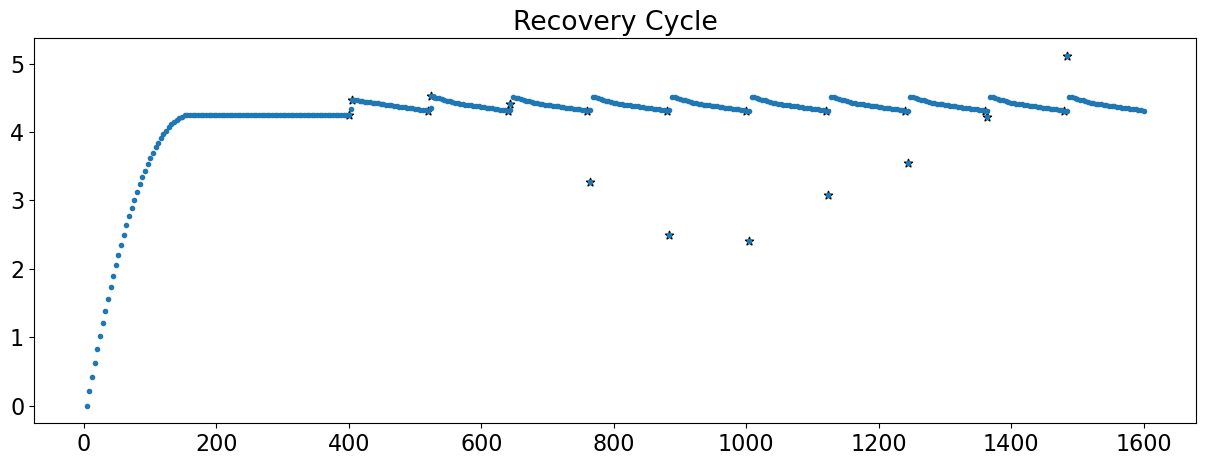

In [15]:
#Recovery Cycle values in between
%matplotlib inline
import stimulationProtocols
prot="DP"
#data_stim=stimulationProtocols.setStimulationProtocol(prot)
#20 pulses at 0.25 Hz -> one pulse every 4 seconds
#to stabilize latency
offset=0
numberPrevPulses=100
vec=[]
for i in range(1,numberPrevPulses+1):
    vec.append(offset+i*4)
lastPulse=offset+numberPrevPulses*4
#extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]#distance to next regular puls
extras=[1.5, 0.75, 0.375, 0.2, 0.125, 0.075, 0.045, 0.035, 0.025, 0.015]
numReg=30#number of regular pulses
for e in extras:
    #one extra pulse
    vec.append(lastPulse+4-e)
    #regular pulses
    for i in range(1,numReg+1):
        vec.append(lastPulse+i*4)
    lastPulse=lastPulse+numReg*4
data_stim=vec


relLatency=convolution.convolution_vec(data_stim, m)
relLatency3=relLatency


#plotten  
fig, ax=plt.subplots(figsize=(15,5))
#"2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"
realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner, in ms!!!!!
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extraOriginal=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]
plt.plot(extraOriginal[::-1],realValues[::-1], linestyle='-', marker='.', label="CMi", color="black", zorder=10)

data_sim=relLatency
numberPrevPulses=100
numberRegPulses=30
if data_sim is not None:
    l=data_sim
    #print(l)
    recoveryCycle3=[]
    
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle3.append(l[i+2]-l[i])
        #print('###')
        #print(l[i])
        #print(l[i+2])
        #print(l[i+2]-l[i])

    #print(recoveryCycle)
    plt.scatter(extras[::-1], recoveryCycle3[::-1], label="Simulation", color="red")
    #ax.set_xticks(extraOriginal)
    #labels=["2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"]
    #ax.set_xticklabels(labels[::-1])
    plt.xlabel("interstimulus interval in s")
    plt.ylabel("slowing in %")

    plt.legend()


plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')

for i in range(numberPrevPulses-1,len(data_sim)-2,numberRegPulses+1):
    plt.scatter(data_stim[i], relLatency[i], marker='*', color="black")
    plt.scatter(data_stim[i+2], relLatency[i+2], marker='*', color="black")
    #print('###')
    #print(data_stim[i])
    #print(data_stim[i+1])
    #print(data_stim[i+2])

plt.title("Recovery Cycle")
plt.show()


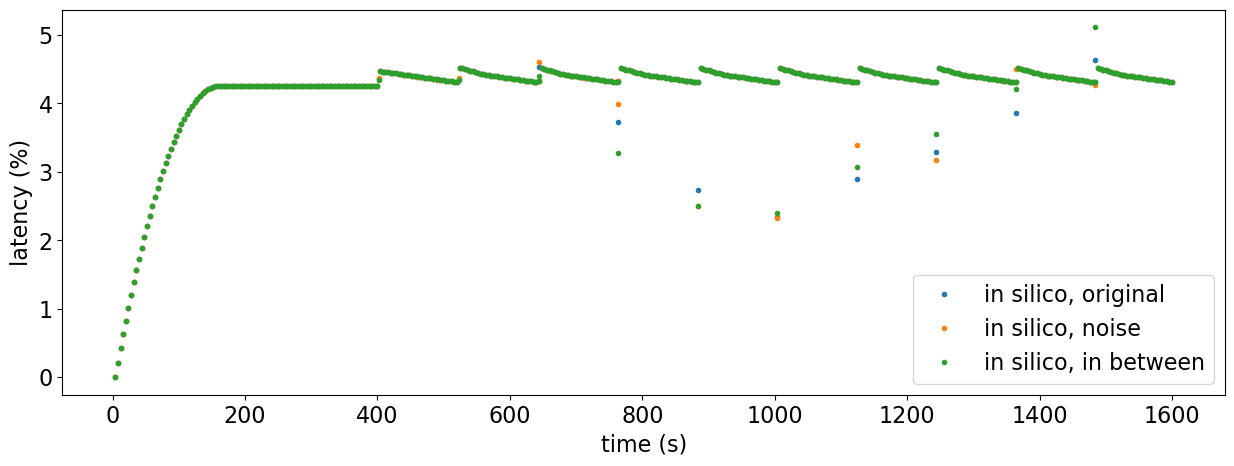

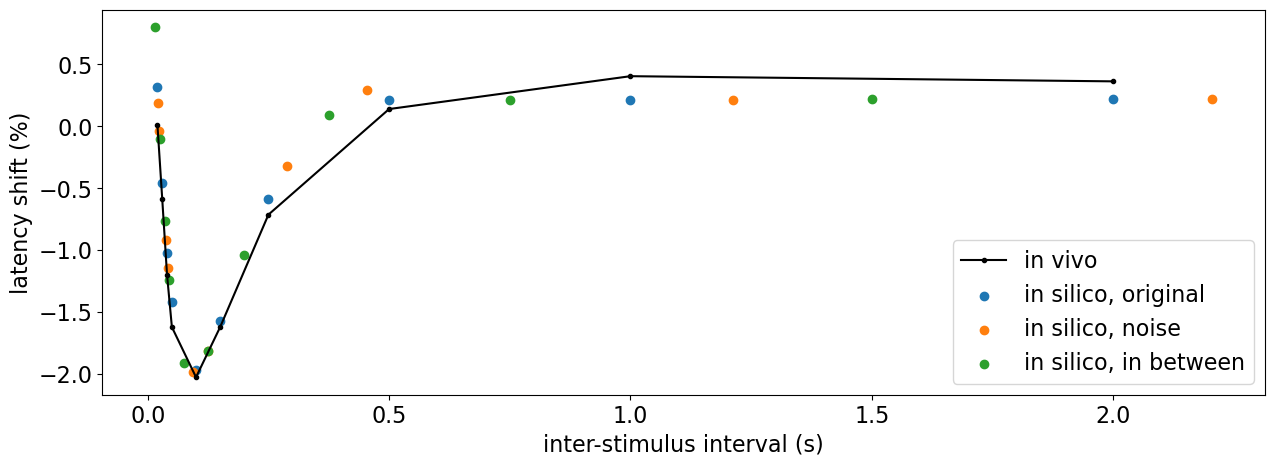

In [16]:
# alle zusammen: Original recovery cycle, in between und noise
#plotten  
plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency0, marker='.', linestyle='none', label="in silico, original")
plt.plot(data_stim, relLatency2, marker='.', linestyle='none', label="in silico, noise")
plt.plot(data_stim, relLatency3, marker='.', linestyle='none', label="in silico, in between")
plt.legend()
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.savefig("Figures/2D_RecoveryCycle_Noise.png", bbox_inches='tight')
plt.show()


plt.rcParams.update({'font.size': 16}) 
fig, ax=plt.subplots(figsize=(15,5))
#"2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"
realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner, in ms!!!!!
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extraOriginal=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]
plt.plot(extraOriginal[::-1],realValues[::-1], linestyle='-', marker='.', label="in vivo", color="black", zorder=10)


plt.scatter([2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02][::-1], recoveryCycle[::-1], label="in silico, original")
plt.scatter(extras2[::-1], recoveryCycle2[::-1], label="in silico, noise")
plt.scatter([1.5, 0.75, 0.375, 0.2, 0.125, 0.075, 0.045, 0.035, 0.025, 0.015][::-1], recoveryCycle3[::-1], label="in silico, in between")

plt.xlabel("inter-stimulus interval (s)")
plt.ylabel("latency shift (%)")

plt.legend()
plt.savefig("Figures/2D_RecoveryCycle_Noise2.png", bbox_inches='tight')
plt.show()
 

Simulation time: 0.0003892683 min


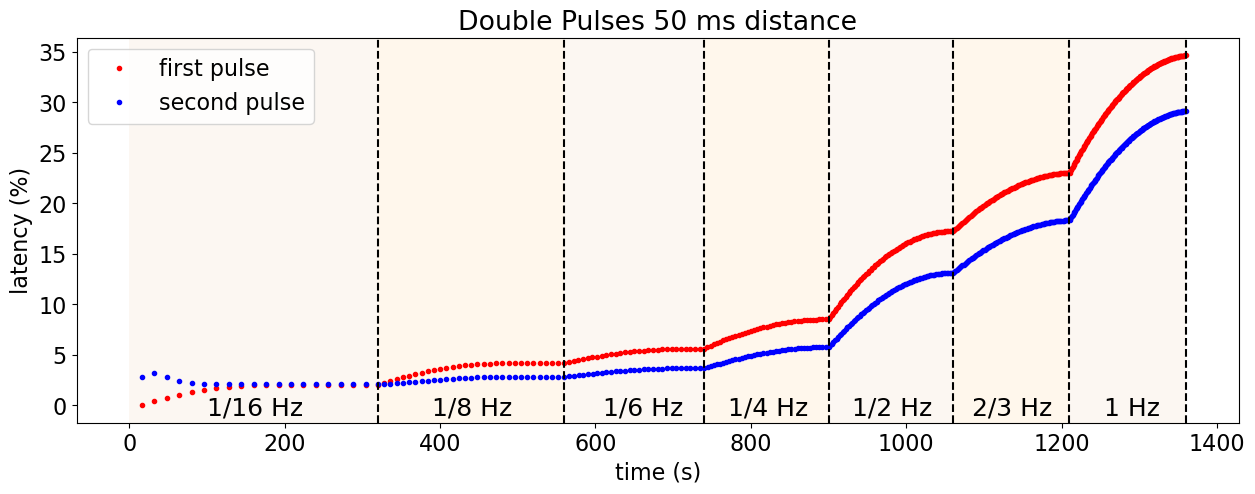

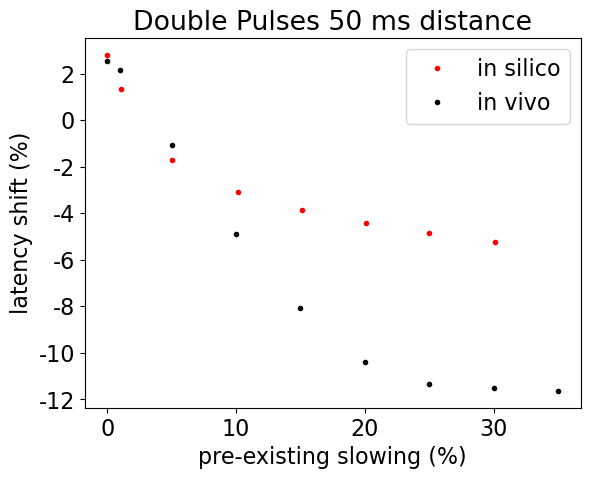

MSE: 17.451502192869324
Root MSE: 4.177499514406833
Normalized Root MSE: 0.2943052495472524
MSE without outliers: 17.44395425701071


In [17]:
#double pulses, distance 50ms
%matplotlib inline
data_stim=stimulationProtocols.setStimulationProtocol("DPNew")
relLatency=convolution.convolution_vec(data_stim, m)
relLatency=np.array(relLatency)
plt.rcParams.update({'font.size': 16})
plt.figure(figsize=(15,5)) 
#plt.plot(impulses, relLatency, marker='.', linestyle='none')
plt.plot(data_stim[::2], relLatency[::2], 'r.', label="first pulse") 
plt.plot(data_stim[1::2], relLatency[1::2], 'b.', label="second pulse") 
plt.title("Double Pulses 50 ms distance")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")

plt.text(100, -1, "1/16 Hz", fontsize=18)
plt.text(390, -1, "1/8 Hz", fontsize=18)
plt.text(610, -1, "1/6 Hz", fontsize=18)
plt.text(770, -1, "1/4 Hz", fontsize=18)
plt.text(930, -1, "1/2 Hz", fontsize=18)
plt.text(1085, -1, "2/3 Hz", fontsize=18)
plt.text(1255, -1, "1 Hz", fontsize=18)
plt.axvline(x=320, color="black", linestyle="dashed")
plt.axvline(x=560, color="black", linestyle="dashed")
plt.axvline(x=740, color="black", linestyle="dashed")
plt.axvline(x=900, color="black", linestyle="dashed")
plt.axvline(x=1060, color="black", linestyle="dashed")
plt.axvline(x=1210, color="black", linestyle="dashed")
plt.axvline(x=1360, color="black", linestyle="dashed")
plt.axvspan(0, 320, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(320, 560, facecolor='#fff0db', alpha=0.5)
plt.axvspan(560, 740, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(740, 900, facecolor='#fff0db', alpha=0.5)
plt.axvspan(900, 1060, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(1060, 1210, facecolor='#fff0db', alpha=0.5)
plt.axvspan(1210, 1360, facecolor='#faf0e6', alpha=0.5)

plt.legend()
plt.savefig("Figures/2D_DoublePulses50_Raw.png", dpi=500, bbox_inches='tight')
plt.show()

plot.plotDoublePulses50(relLatency, savefile="Figures/2D_DoublePulses50.png")

320
560
740
900
1060
1210.0
1360.0
Simulation time: 0.0004021817 min


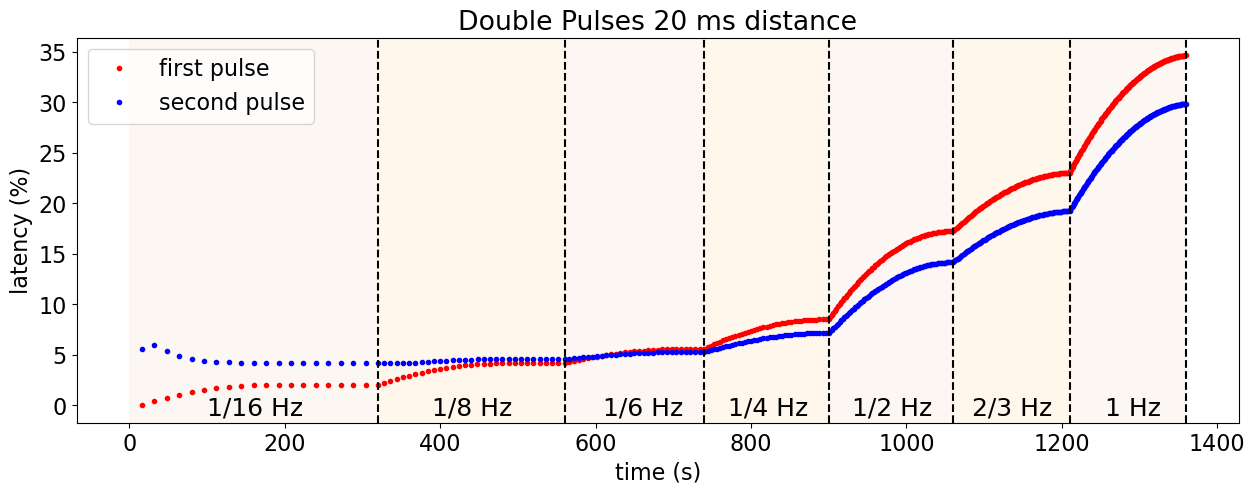

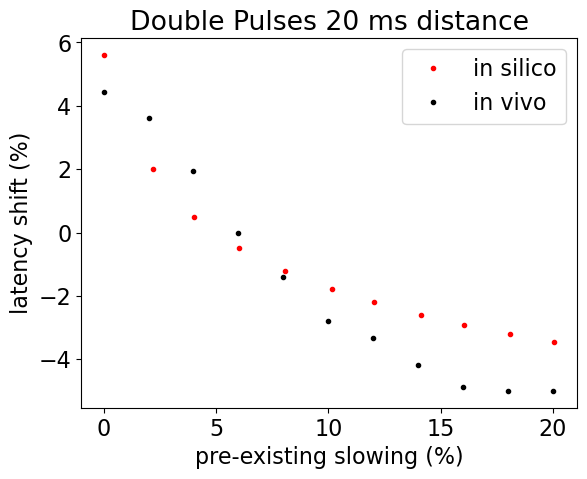

MSE: 1.867878212387462
Root MSE: 1.3667034105421199
Normalized Root MSE: 0.14470977288093034
MSE without outliers: 1.7454692759723829


In [18]:
#double pulses, distance 20ms
impulses=stimulationProtocols.setStimulationProtocol("DPNew2")
#print(impulses)
relLatency=convolution.convolution_vec(impulses, m)
plt.rcParams.update({'font.size': 16})
plt.figure(figsize=(15,5)) 
#plt.plot(impulses, relLatency, marker='.', linestyle='none')
plt.plot(impulses[::2], relLatency[::2], 'r.', label="first pulse") 
plt.plot(impulses[1::2], relLatency[1::2], 'b.', label="second pulse")
plt.title("Double Pulses 20 ms distance")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")

#plt.title('       1/16 Hz                1/8 Hz         1/6 Hz       1/4 Hz      1/2 Hz   1/1.5 Hz    1 Hz', fontdict = {'fontsize' : 18})
plt.text(100, -1, "1/16 Hz", fontsize=18)
plt.text(390, -1, "1/8 Hz", fontsize=18)
plt.text(610, -1, "1/6 Hz", fontsize=18)
plt.text(770, -1, "1/4 Hz", fontsize=18)
plt.text(930, -1, "1/2 Hz", fontsize=18)
plt.text(1085, -1, "2/3 Hz", fontsize=18)
plt.text(1255, -1, "1 Hz", fontsize=18)
plt.axvline(x=320, color="black", linestyle="dashed")
plt.axvline(x=560, color="black", linestyle="dashed")
plt.axvline(x=740, color="black", linestyle="dashed")
plt.axvline(x=900, color="black", linestyle="dashed")
plt.axvline(x=1060, color="black", linestyle="dashed")
plt.axvline(x=1210, color="black", linestyle="dashed")
plt.axvline(x=1360, color="black", linestyle="dashed")
plt.axvspan(0, 320, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(320, 560, facecolor='#fff0db', alpha=0.5)
plt.axvspan(560, 740, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(740, 900, facecolor='#fff0db', alpha=0.5)
plt.axvspan(900, 1060, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(1060, 1210, facecolor='#fff0db', alpha=0.5)
plt.axvspan(1210, 1360, facecolor='#faf0e6', alpha=0.5)

plt.legend()
plt.savefig("Figures/2D_DoublePulses20_Raw.png", dpi=500, bbox_inches='tight')
plt.show()

plot.plotDoublePulses20(relLatency, savefile="Figures/2D_DoublePulses20.png")


Simulation time: 0.0009717233 min


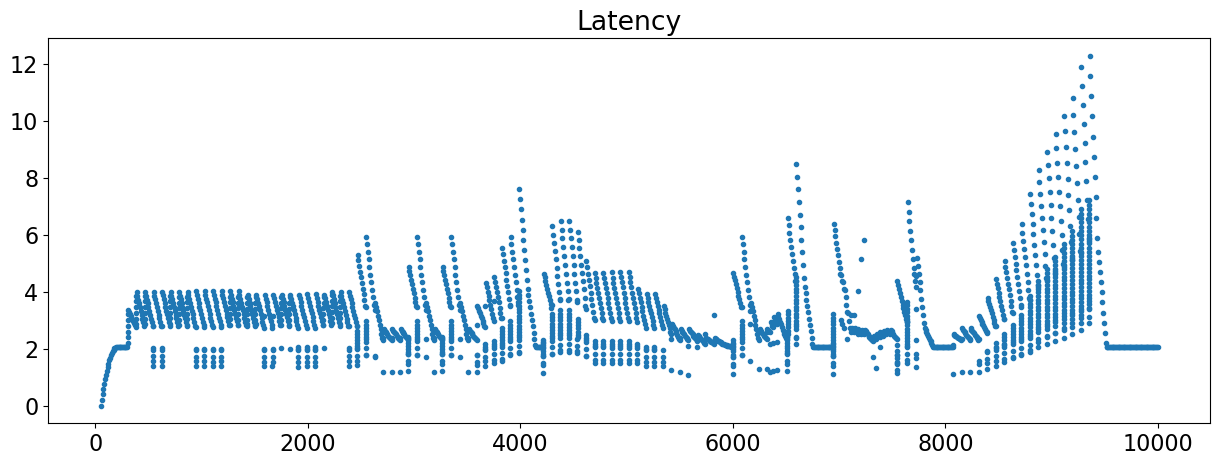

In [19]:
import pandas as pd
#Protocol von Roberto
data = pd.read_csv('stimuli_Roberto.txt', sep=" ")
data["Time"]=data["Time"].astype(float)
data = data.sort_values(by="Time", ascending=True)
data = data.reset_index(drop=True)
impulses = data.to_numpy()
impulses=data.iloc[:]["Time"].values
relLatency=convolution.convolution_vec(impulses, m)
plt.figure(figsize=(15,5)) 
plt.plot(impulses, relLatency, marker='.', linestyle='none')
plt.title("Latency")
plt.show()

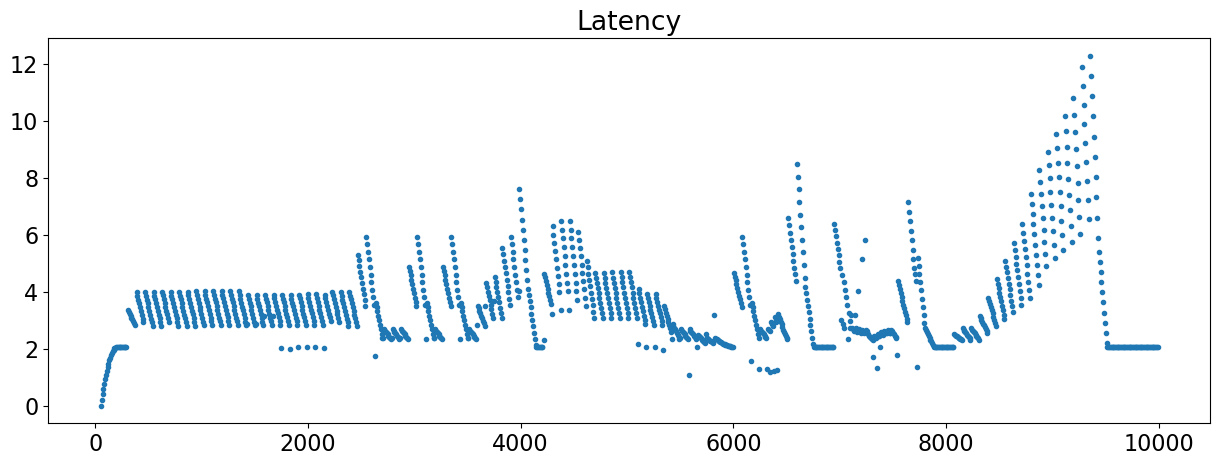

In [20]:
#filter out extra pulses
#print(impulses)
indexRegularPulses=[]
for i in range(len(impulses)-1):
    if impulses[i+1]-impulses[i]>=4:
        indexRegularPulses.append(i)
#print(indexRegularPulses)

impulses = np.array(impulses)
indexRegularPulses = np.array(indexRegularPulses)
relLatency = np.array(relLatency)

plt.figure(figsize=(15,5)) 
plt.plot(impulses[indexRegularPulses],relLatency[indexRegularPulses], marker='.', linestyle='none')
plt.title("Latency")
plt.show()

Simulation time: 0.0000539067 min


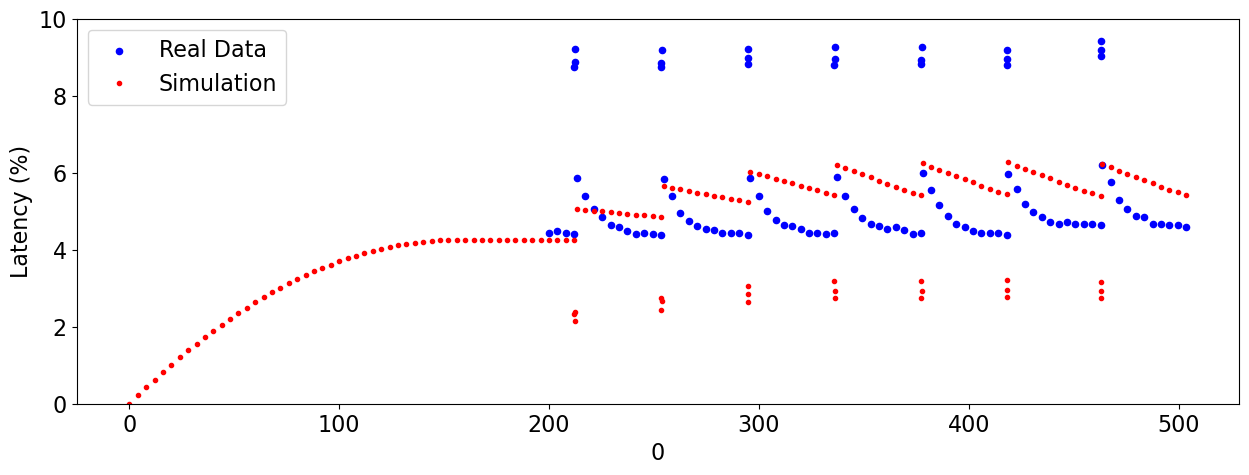

In [21]:
data_aps = np.genfromtxt('Data/ExtraPulses_timestamps_aps.txt', delimiter="", names=["aps"])
data_stim = np.genfromtxt('Data/ExtraPulses_timestamps_stim.txt', delimiter="", names=["stim"])

l = np.zeros((len(data_stim)-1,2))
j=0
i=0
while i < len(data_stim):
    if j < len(data_aps):
        point = data_aps['aps'][j]-data_stim['stim'][i]
        if point>0.13:
            l[i][0]=data_aps['aps'][j]
            l[i][1]=(point*1000)
            j=j+1
            i=i+1
        else:
            j=j+1
    else:
        break

data = pd.DataFrame(l)

data=data[280:383]
data[0]=(data[0]-843.78955+200)
data[1]=((data[1]/148.5)-1)*100
data2=data[0]
new = pd.DataFrame({0: np.arange(0, 200, 4)})
data2 = pd.concat([new, data2], ignore_index=True)
#print(data)

relLatency=convolution.convolution_vec(data2[0], m)

fig, ax1 = plt.subplots(figsize=(15, 5))
data.plot.scatter(x=0, y=1, ax=ax1, color='blue', label='Real Data')
#ax1.set_ylabel("Latency (ms)")

#ax2 = ax1.twinx()  
ax1.plot(data2[0], relLatency, marker='.', linestyle='none', color='red', label='Simulation')
ax1.set_ylabel("Latency (%)")
#ax1.tick_params(axis='y')
#ax1.legend(loc=1)
ax1.legend()
#ax1.set_ylim(139, 163)
ax1.set_ylim(0, 10)
#ax2.set_ylim(0, 10)

plt.show()


Simulation time: 0.0000242850 min


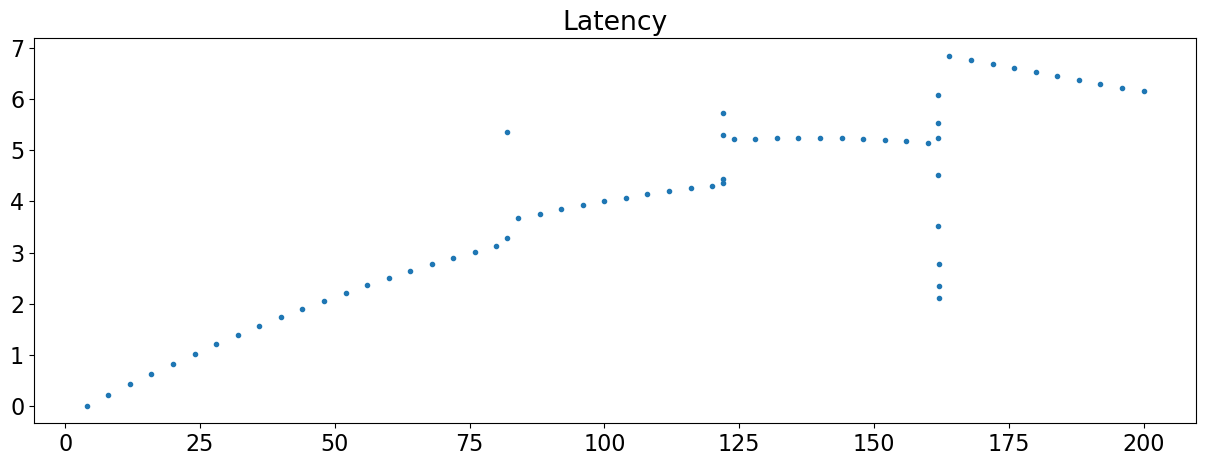

In [22]:
impulses=stimulationProtocols.setStimulationProtocol("FF_100Hz_ADS")
relLatency=convolution.convolution_vec(impulses, m)
plt.figure(figsize=(15,5)) 
plt.plot(impulses, relLatency, marker='.', linestyle='none')
plt.title("Latency")
plt.show()

Simulation time: 0.0000306533 min
Simulation time: 0.0000316367 min
Simulation time: 0.0000326883 min
Simulation time: 0.0000311767 min
Simulation time: 0.0000291000 min


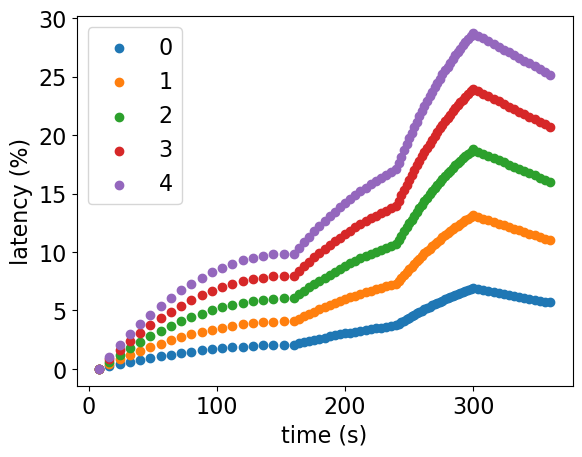

In [23]:
data=stimulationProtocols.setStimulationProtocol(11)
#print(data)
data_stim=stimulationProtocols.setStimulationProtocol(11)


for i in range(5):
    relLatency=convolution.convolution_vec(data, m)
    #print(relLatency)
    
    relLatency = np.array(relLatency)
    
    #plt.scatter(data_stim, relLatency, label=str(i))
    
    #startingLatency=200
    #latency=(relLatency2*startingLatency/100)
    #print(latency)
    #data=[sum(x) for x in zip(data, latency)]
    
    data=data*relLatency/100+data
    #print(data)
    data_stim = np.array(data_stim)
    data = np.array(data)
    #plt.scatter(data_stim, 200+data-data_stim, label=str(i))#latency in ms
    #plt.scatter(data_stim, (data-data_stim)/200*100, label=str(i))#latency in %
    if i==0:
        totalLatency=relLatency
    else:
        totalLatency=totalLatency+relLatency
    plt.scatter(data_stim, totalLatency, label=str(i))#latency in %

#data_stim=stimulationProtocols.setStimulationProtocol(11)
#print(data_stim)
#print(data)
#plt.scatter(data_stim, relLatency)
plt.xlabel('time (s)')
plt.ylabel('latency (%)')
plt.legend()
plt.show()

Simulation time: 0.0001382550 min
Simulation time: 0.0001288000 min
Simulation time: 0.0001882900 min
Simulation time: 0.0001348917 min
Simulation time: 0.0001482567 min


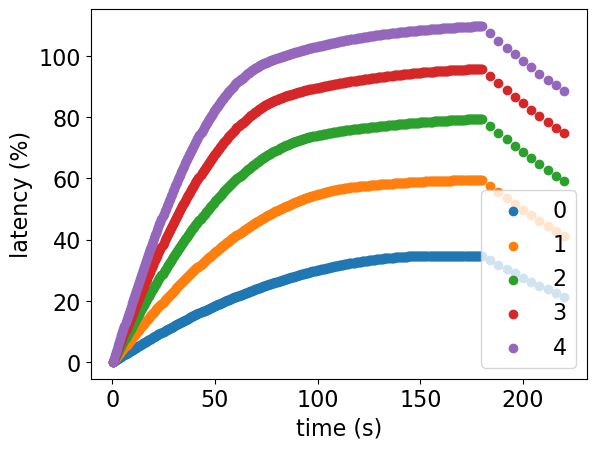

In [24]:
data=stimulationProtocols.setStimulationProtocol(15)
#print(data)
data_stim=stimulationProtocols.setStimulationProtocol(15)

totalLatency=[]
for i in range(5):
    relLatency=convolution.convolution_vec(data, m)
    #print(relLatency)
    #plt.scatter(data_stim, relLatency, label=str(i))
    relLatency = np.array(relLatency)
    #print(relLatency)
    #startingLatency=200
    #latency=(relLatency*startingLatency/100)
    #print(latency)
    #data=[sum(x) for x in zip(data, latency)]
    
    data=data*relLatency/100+data
    #print(data)
    data_stim = np.array(data_stim)
    data = np.array(data)
    #plt.scatter(data_stim, 200+data-data_stim, label=str(i))#latency in ms
    #plt.scatter(data_stim, (data-data_stim)/200*100, label=str(i))#latency in %
    if i==0:
        totalLatency=relLatency
    else:
        totalLatency=totalLatency+relLatency
    plt.scatter(data_stim, totalLatency, label=str(i))#latency in %
    

#data_stim=stimulationProtocols.setStimulationProtocol(11)
#print(data_stim)
#print(data)
#plt.scatter(data_stim, relLatency)
plt.xlabel('time (s)')
plt.ylabel('latency (%)')
plt.legend()
plt.show()

In [25]:
# stim_new=stimulationProtocols.setStimulationProtocol(11)
#print("stim: ",stim_new)
stim_original=stimulationProtocols.setStimulationProtocol(11)


totalLatency=[]
#totalLatencyS=[]
for i in range(100):
    relLatency=convolution.convolution_vec(stim_new, m)#calculate latency in %
    relLatency = np.array(relLatency)
    #print(relLatency)
    #print("Latency: ",relLatency)
    startingLatency=0.2 #in s
    latency_shift=(startingLatency*relLatency/100) #in s; how much the latency is shifted
    #print("latency_shift: ",latency_shift)
    stim_new=[sum(x) for x in zip(stim_new, latency_shift)]# add the latency shift to the stim times to get the new stim times
    stim_new = np.array(stim_new)
    #print("stim: ",stim_new)
    #print(stim_new)
    if i==0:
        totalLatency=relLatency
        #totalLatencyS=(startingLatency*relLatency/100)+startingLatency
    else:
        totalLatency=totalLatency+relLatency
        #totalLatencyS=totalLatencyS+(startingLatency*relLatency/100)+startingLatency
    
    total=totalLatency/(i+1)
    #print(totalS)
    #print("TotalLatency: ",total)
    plt.scatter(stim_original, total, label=str(i))#latency in %
    #plt.scatter(stim_original, totalLatencyS, label=str(i))#latency in s
    

plt.xlabel('time (s)')
plt.ylabel('latency (%)')
#plt.legend()
plt.show()


NameError: name 'stim_new' is not defined

In [ ]:
stim_new=stimulationProtocols.setStimulationProtocol(15)
#print("stim: ",stim_new)
stim_original=stimulationProtocols.setStimulationProtocol(15)


totalLatency=[]
#totalLatencyS=[]
for i in range(100):
    relLatency=convolution.convolution_vec(stim_new, m)#calculate latency in %
    relLatency = np.array(relLatency)
    #print("Latency: ",relLatency)
    startingLatency=0.5 #in s
    latency_shift=(startingLatency*relLatency/100) #in s; how much the latency is shifted
    #print("latency_shift: ",latency_shift)
    stim_new=[sum(x) for x in zip(stim_new, latency_shift)]# add the latency shift to the stim times to get the new stim times
    stim_new = np.array(stim_new)
    #print("stim: ",stim_new)
    if i==0:
        totalLatency=relLatency
        #totalLatencyS=(startingLatency*relLatency/100)+startingLatency
    else:
        totalLatency=totalLatency+relLatency
        #totalLatencyS=totalLatencyS+(startingLatency*relLatency/100)+startingLatency
    
    total=totalLatency/(i+1)
    #print(totalS)
    #print("TotalLatency: ",total)
    plt.scatter(stim_original, total, label=str(i))#latency in %
    #plt.scatter(stim_original, totalLatencyS, label=str(i))#latency in s
    

plt.xlabel('time (s)')
plt.ylabel('latency (%)')
#plt.legend()
plt.show()


In [ ]:
stim_new=stimulationProtocols.setStimulationProtocol("DP")
#print("stim: ",stim_new)
stim_original=stimulationProtocols.setStimulationProtocol("DP")
num_datasets=10
cmap = cm.get_cmap('plasma', num_datasets)

allLatencies=[]
allStims=[]
totalLatency=[]
for i in range(num_datasets):
    allStims.append(stim_new)
    relLatency=convolution.convolution_vec(stim_new, m)#calculate latency in %
    relLatency = np.array(relLatency)
    #print(relLatency)
    #print("Latency: ",relLatency)
    startingLatency=0.5 #in s
    latency_shift=(startingLatency*relLatency/100) #in s; how much the latency is shifted
    #print("latency_shift: ",latency_shift)
    stim_new=[sum(x) for x in zip(stim_new, latency_shift)]# add the latency shift to the stim times to get the new stim times
    stim_new = np.array(stim_new)
    #print("stim: ",stim_new)
    #print(stim_new)
    if i==0:
        totalLatency=relLatency
    else:
        totalLatency=totalLatency+relLatency
    
    total=totalLatency/(i+1)
    allLatencies.append(total)
    #print("TotalLatency: ",total)
    
    dataset_color = cmap(i / (num_datasets - 1))
    # Generate gradient colors within each dataset
    norm = mcolors.Normalize(vmin=0, vmax=len(stim_original))
    cmap_gradient = cm.get_cmap('Blues')  # Colormap for gradient within each dataset
    colors = cmap_gradient(norm(range(len(stim_original))))
    
    # Blend the dataset color with the gradient
    colors = [mcolors.to_rgba(dataset_color, alpha=1.0) for _ in range(len(stim_original))]
    plt.scatter(stim_original, total, label=str(i), color=colors)#latency in %
    

plt.xlabel('time (s)')
plt.ylabel('latency (%)')
#plt.legend()
plt.show()




In [ ]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

#plotten  
fig, ax=plt.subplots(figsize=(15,5))
#"2000", "1000", "500", "250", "150", "100", "50", "40", "30", "20"
realValues=[1.646, 1.835, 0.633, -3.23, -7.342, -9.177, -7.342,  -5.443, -2.658, 0.063]#Weidner, in ms!!!!!
realValues=np.array(realValues)/453*100# in %, sehr grob umgerechnet, 453 ist die durchschnittliche Grundlatenz aller Fasern, berechnet aus mean conduction velocity und mean conduction distances
extraOriginal=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]
plt.plot(extraOriginal[::-1],realValues[::-1], linestyle='-', marker='.', label="CMi", color="black", zorder=10)

norm = mcolors.Normalize(vmin=0, vmax=len(extraOriginal))
cmap = cm.get_cmap('plasma')  # other colormaps 'plasma', 'cividis', etc.
colors = cmap(norm(range(len(extraOriginal))))

for j in range(10):
    data_sim=allLatencies[j]
    stim=allStims[j]
    numberPrevPulses=100
    numberRegPulses=30
    if data_sim is not None:
        l=data_sim
        #print(l)
        recoveryCycle4=[]
        extraPulses4=[]

        for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
            recoveryCycle4.append(l[i+2]-l[i])
            extraPulses4.append(stim[i+2]-stim[i+1])
            
            #print('###')
            #print(l[i])
            #print(l[i+2])
            #print(l[i+2]-l[i])
        #print(extraPulses4)
        #print(recoveryCycle)
        plt.scatter(extraPulses4[::-1], recoveryCycle4[::-1], label=j, color=colors)

plt.xlabel("interstimulus interval in s")
plt.ylabel("slowing in %")

#plt.legend()


In [ ]:
def setStimulationProtocolDP():
    vec=[]
    offset=0
    numberPrevPulses=100
    for i in range(1,numberPrevPulses+1):
        vec.append(offset+i*4)
    lastPulse=offset+numberPrevPulses*4
    #extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02, 0.015]#distance to next regular puls
    extras=[0.3]#distance to next regular puls
    numReg=30#number of regular pulses
    for e in extras:
        #one extra pulse
        vec.append(lastPulse+4-e)
        #regular pulses
        for i in range(1,numReg+1):
            vec.append(lastPulse+i*4)
        lastPulse=lastPulse+numReg*4
    return vec

In [ ]:
#data=stimulationProtocols.setStimulationProtocol("DP")
#print(data)
#data_stim=stimulationProtocols.setStimulationProtocol("DP")
data=setStimulationProtocolDP()
data_stim=setStimulationProtocolDP()
#print(data_stim)
print(data_stim[99])
print(data_stim[100])
print(data_stim[101])


for i in range(1):
    relLatency=convolution.convolution_vec(data, m)
    #print(relLatency)
    print(relLatency[99])
    print(relLatency[100])
    print(relLatency[101])
    #plt.scatter(data_stim, relLatency, label=str(i))
    relLatency = np.array(relLatency)
    data=data*relLatency/100+data
    
    data_stim = np.array(data_stim)
    #print(data)
    print(data[99])
    print(data[100])
    print(data[101])
    data = np.array(data)
    #print((data-data_stim)/200*100)
    #plt.scatter(data_stim, 200+data-data_stim, label=str(i))#latency in ms
    #plt.scatter(data_stim, relLatency, label=str(i))#latency in %
    if i==0:
        totalLatency=relLatency
    else:
        totalLatency=totalLatency+relLatency
    plt.scatter(data_stim, totalLatency, label=str(i))#latency in %

#data_stim=stimulationProtocols.setStimulationProtocol(11)
#print(data_stim)
#print(data)
#plt.scatter(data_stim, relLatency)
plt.xlabel('time (s)')
plt.ylabel('latency (%)')
plt.legend()
plt.show()